# Contención de incendios forestales con DQN (CNN) + SimFire

**Aprendizaje por Refuerzo I - UBA (MIA 2026) - Trabajo final**

**Problema:** un agente decide, turno a turno, en qué celda de una grilla poner un
cortafuego mientras el fuego se propaga (según viento y combustible). El objetivo es
minimizar el área quemada.

**Qué hace este notebook:**
1. Instala SimFire (el simulador de incendios del proyecto Fireline de MITRE).
2. Arma un entorno con interfaz tipo Gym (`reset` / `step`) arriba de SimFire.
3. Implementa DQN y Double DQN con una CNN que lee el mapa como una imagen.
4. Entrena los dos agentes, grafica la convergencia y los compara contra dos baselines
   (no hacer nada y poner cortafuegos al azar) y una heurística simple.

## 1. Instalación e imports

**Ojo con esto (fue el primer problema):** `simfire` en PyPI declara `python ~=3.9`, y
Colab usa Python 3.12, así que `pip install simfire` a secas falla. Lo que hice es
instalarlo con `--no-deps --ignore-requires-python` y después instalar a mano las
dependencias que sí hacen falta.

Además `simfire` importa `landfire`, `geotiff`, `geopandas` y `geopy`, que solo se usan
para bajar mapas reales de EEUU y no se pueden instalar en Python 3.12. Como yo uso
terreno generado por funciones (no mapas reales), los reemplazo por módulos vacíos
antes de importar simfire.

In [1]:
import os
import sys
import types
import random
import subprocess
import time
import json

os.environ["SDL_VIDEODRIVER"] = "dummy"   # pygame sin ventana (Colab no tiene pantalla)


def instalar(*paquetes):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes])


# pip es idempotente, si ya está instalado no hace nada
instalar("--no-deps", "--ignore-requires-python", "simfire==2.0.1")
instalar("noise", "reportlab", "svglib", "wurlitzer", "jsonlines", "pygame",
         "networkx", "h5py", "pyyaml", "rich", "setuptools<81")


def modulo_falso(nombre, **atributos):
    modulo = types.ModuleType(nombre)
    modulo.__dict__.update(atributos)
    sys.modules[nombre] = modulo


modulo_falso("landfire")
modulo_falso("landfire.product")
modulo_falso("landfire.product.enums", ProductRegion=None, ProductTheme=None, ProductVersion=None)
modulo_falso("landfire.product.search", ProductSearch=None)
modulo_falso("geopandas")
modulo_falso("geopy")
modulo_falso("geopy.distance", great_circle=None)
modulo_falso("geotiff", GeoTiff=None)

import copy
import logging
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

from simfire.sim.simulation import FireSimulation
from simfire.utils.config import Config
from simfire.enums import BurnStatus, FuelConstants

# simfire loguea bastante, lo bajo para que no ensucie la salida
logging.getLogger().setLevel(logging.ERROR)
for nombre_log in list(logging.root.manager.loggerDict):
    if nombre_log.startswith("simfire"):
        logging.getLogger(nombre_log).setLevel(logging.ERROR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


## 2. Parámetros

Dejo todos los parámetros juntos acá arriba para poder tocarlos fácil.
`MODO_RAPIDO = True` sirve para probar que todo corre en 1-2 minutos antes de lanzar
el entrenamiento de verdad.

In [2]:
MODO_RAPIDO = False

# --- entorno ---
TAM = 16               # la grilla es de TAM x TAM celdas
PIXEL_SCALE = 300      # pies por celda. Más grande = el fuego avanza más lento (en celdas)
HUMEDAD = 0.08         # humedad del combustible (con 0.03 el fuego se come los cortafuegos)
VIENTO_MPH = 8         # velocidad del viento
MAX_PASOS = 100        # máximo de turnos por episodio
VARIAR_TERRENO = False  # True = cambia también combustible y elevación en cada episodio
BONUS_FRONTERA = 0.3   # reward shaping: bonus por poner el cortafuego pegado a una celda ardiendo
BONUS_FIN = 0.05       # valor final del bonus en el agente "DQN bonus decreciente"
DECAE_DESDE = 300      # episodio en el que el bonus empieza a bajar
DECAE_HASTA = 800      # episodio en el que el bonus llega a BONUS_FIN
SOLO_AGENTES = None    # ej: ["DQN bonus decreciente"] entrena solo ese agente (None = todos)

# --- DQN ---
TIPO_RED = "conv"      # "conv" (totalmente convolucional) o "fc" (CNN + capa densa)
EPISODIOS = 1500
GAMMA = 0.9    # horizonte corto: el efecto de un cortafuego se ve en pocos pasos
LR = 5e-5      # bajé el learning rate (con 1e-4 el DQN aprendía rápido y se desestabilizaba)
BATCH = 64
TAM_BUFFER = 30000
PASOS_ANTES_DE_APRENDER = 1000
APRENDER_CADA = 2          # pasos del entorno por cada actualización de la red
ACTUALIZAR_TARGET_CADA = 1000   # target más quieto = objetivos más estables
EPSILON_INI = 1.0
EPSILON_FIN = 0.05
EPSILON_PASOS = 40000      # pasos en los que epsilon baja linealmente

EVAL_CADA = 100            # cada cuántos episodios evalúo sin azar
SEMILLAS_ENTRENAMIENTO = [0, 1, 2]   # repetimos cada agente con varias semillas
SEMILLAS_EVALUACION = list(range(100000, 100050))   # 50 escenarios fijos para comparar
SEMILLAS_VALIDACION = list(range(200000, 200040))   # 40 escenarios para elegir el mejor checkpoint

CARPETA_RESULTADOS = "resultados"

# En Colab el disco es temporal: si la sesión se cae se pierde todo lo guardado.
# Con GUARDAR_EN_DRIVE = True los resultados van a tu Google Drive (Colab te va a pedir
# autorización en una ventana cuando corra esta celda).
GUARDAR_EN_DRIVE = False
if GUARDAR_EN_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CARPETA_RESULTADOS = "/content/drive/MyDrive/incendios_resultados"
    except ImportError:
        print("No estoy en Colab, guardo en la carpeta local 'resultados'")

if MODO_RAPIDO:
    EPISODIOS = 40
    EVAL_CADA = 20
    DECAE_DESDE = 10
    DECAE_HASTA = 30
    EPSILON_PASOS = 1500
    PASOS_ANTES_DE_APRENDER = 200
    SEMILLAS_ENTRENAMIENTO = [0]
    SEMILLAS_EVALUACION = list(range(100000, 100005))
    SEMILLAS_VALIDACION = list(range(200000, 200003))

if SOLO_AGENTES:
    CARPETA_RESULTADOS += "_parcial"   # así una corrida parcial no pisa los resultados completos
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

## 3. El entorno

SimFire ya trae el simulador del fuego (modelo de Rothermel: depende del combustible,
humedad, viento y pendiente). Lo único que hago es envolverlo en una clase con
`reset()` y `step()`.

- **Acción:** un número de 0 a TAM*TAM-1 = la celda donde pongo un cortafuego.
  Después de cada acción el fuego avanza 1 minuto simulado.
- **Observación:** una "imagen" de 9 canales de TAM x TAM:
  - 4 canales con el estado de cada celda (sin quemar, quemándose, quemada, cortafuego)
  - 1 canal con el combustible
  - 1 canal con la elevación
  - 3 canales constantes con el viento (velocidad, seno y coseno de la dirección)
- **Recompensa:** `-0.1` por cada celda que se prende fuego en ese turno.
  Así, maximizar la recompensa total = minimizar el área quemada.
  - **Reward shaping:** con solo esa recompensa DQN aprende muy poco: en las primeras
    pruebas el EVAL se quedó en el nivel del azar durante 1500 episodios y, ya con los
    hiperparámetros finales, mejora lento (~120 celdas quemadas contra ~142 del azar).
    Probablemente porque el efecto de un cortafuego aparece varios pasos después y se
    pierde entre el ruido. Por eso se agrega un bonus `BONUS_FRONTERA` cuando el
    cortafuego se pone pegado a una celda ardiendo. Las curvas y la evaluación siguen
    midiendo solo el área quemada. `DQN sin shaping` queda como comparación.
- **Escenarios:** en cada episodio cambian el punto de ignición y la dirección del
  viento (8 direcciones), para que el agente no se memorice un solo caso.

In [3]:
SIN_QUEMAR = int(BurnStatus.UNBURNED)
QUEMANDOSE = int(BurnStatus.BURNING)
QUEMADA = int(BurnStatus.BURNED)
CORTAFUEGO = int(BurnStatus.FIRELINE)

N_CANALES = 9
N_ACCIONES = TAM * TAM


def armar_config(semilla):
    """Arma el diccionario de configuración de SimFire para un escenario."""
    rng = np.random.default_rng(semilla)
    inicio_x = int(rng.integers(TAM // 4, 3 * TAM // 4))
    inicio_y = int(rng.integers(TAM // 4, 3 * TAM // 4))
    direccion_viento = float(rng.choice(np.arange(0, 360, 45)))

    semilla_elevacion = 827
    semilla_combustible = 1113
    if VARIAR_TERRENO:
        semilla_elevacion = int(rng.integers(0, 10000))
        semilla_combustible = int(rng.integers(0, 10000))

    config = {
        "area": {"screen_size": [TAM, TAM], "pixel_scale": PIXEL_SCALE},
        "display": {"fire_size": 2, "control_line_size": 2, "agent_size": 4},
        "simulation": {"update_rate": 1, "runtime": "24h", "headless": True,
                       "draw_spread_graph": False, "record": False, "save_data": False,
                       "data_type": "npy", "sf_home": "/tmp/simfire_home"},
        "mitigation": {"ros_attenuation": True},
        "operational": {"seed": None, "latitude": 39.67, "longitude": -119.8,
                        "height": 400, "width": 400, "resolution": 30, "year": 2020},
        "terrain": {
            "topography": {"type": "functional", "functional": {
                "function": "perlin",
                "perlin": {"octaves": 3, "persistence": 0.7, "lacunarity": 2.0,
                           "seed": semilla_elevacion, "range_min": 100.0, "range_max": 300.0},
                "gaussian": {"amplitude": 500, "mu_x": 50, "mu_y": 50, "sigma_x": 50, "sigma_y": 50}}},
            "fuel": {"type": "functional", "functional": {
                "function": "chaparral", "chaparral": {"seed": semilla_combustible}}}},
        "fire": {"fire_initial_position": {"type": "static",
                                           "static": {"position": (inicio_x, inicio_y)},
                                           "random": {"seed": 0}},
                 "max_fire_duration": 4, "diagonal_spread": True},
        "environment": {"moisture": HUMEDAD},
        "wind": {"function": "simple",
                 "simple": {"speed": VIENTO_MPH, "direction": direccion_viento},
                 "perlin": {"speed": {"seed": 1, "scale": 400, "octaves": 3, "persistence": 0.7,
                                      "lacunarity": 2.0, "range_min": 7, "range_max": 47},
                            "direction": {"seed": 2, "scale": 1500, "octaves": 2, "persistence": 0.9,
                                          "lacunarity": 1.0, "range_min": 0.0, "range_max": 360.0}}},
    }
    return config, direccion_viento


class EntornoIncendio:
    def __init__(self, bonus=0.0):
        # bonus = reward shaping (0 = recompensa original, solo el área quemada)
        self.bonus = bonus
        self.sim = None
        # contadores para el diagnóstico (no se reinician en reset): ¿qué % de los
        # cortafuegos se pone pegado al fuego?
        self.total_lineas = 0
        self.total_frontera = 0

    def reset(self, semilla=None):
        if semilla is None:
            semilla = int(np.random.randint(0, 10_000_000))
        config, direccion = armar_config(semilla)
        self.sim = FireSimulation(Config(config_dict=config))
        self.pasos = 0
        self.lineas = 0
        self.activo = True
        self.ret_area = 0.0   # recompensa acumulada SIN el bonus (para graficar y comparar)

        # Estos canales no cambian durante el episodio, los calculo una sola vez
        combustible = self.sim.get_attribute_data()["w_0"].astype(np.float32)
        combustible = combustible / FuelConstants.W_0_MAX
        elevacion = np.array(self.sim.terrain.elevations, dtype=np.float32)
        elevacion = (elevacion - elevacion.min()) / (elevacion.max() - elevacion.min() + 1e-6)
        rad = np.deg2rad(direccion)
        viento = np.stack([np.full((TAM, TAM), VIENTO_MPH / 20.0),
                           np.full((TAM, TAM), np.sin(rad)),
                           np.full((TAM, TAM), np.cos(rad))]).astype(np.float32)
        self.canales_fijos = np.concatenate([combustible[None], elevacion[None], viento])

        self.quemadas_antes = self.area_quemada()
        return self.observar()

    def area_quemada(self):
        mapa = self.sim.fire_map
        return int(((mapa == QUEMANDOSE) | (mapa == QUEMADA)).sum())

    def observar(self):
        mapa = self.sim.fire_map
        estado = np.stack([mapa == SIN_QUEMAR, mapa == QUEMANDOSE,
                           mapa == QUEMADA, mapa == CORTAFUEGO]).astype(np.float32)
        return np.concatenate([estado, self.canales_fijos])

    def step(self, accion):
        """accion = índice de celda (0..TAM*TAM-1) o None para no poner nada."""
        recompensa = 0.0   # parte "real" de la recompensa (área quemada)
        bonus = 0.0        # parte del reward shaping
        if accion is not None:
            fila, columna = divmod(int(accion), TAM)
            if self.sim.fire_map[fila, columna] == SIN_QUEMAR:
                # ¿hay alguna celda ardiendo pegada a esta (8 vecinas)?
                vecinas = self.sim.fire_map[max(0, fila - 1):fila + 2, max(0, columna - 1):columna + 2]
                pegada_al_fuego = bool((vecinas == QUEMANDOSE).any())
                if pegada_al_fuego:
                    bonus = self.bonus
                    self.total_frontera += 1
                # update_mitigation espera (columna, fila, tipo)
                self.sim.update_mitigation([(columna, fila, BurnStatus.FIRELINE)])
                self.lineas += 1
                self.total_lineas += 1
            else:
                recompensa -= 0.5   # celda inválida (el agente la evita con la máscara)

        _, self.activo = self.sim.run(1)    # el fuego avanza 1 minuto
        self.pasos += 1

        terminado = (not self.activo) or (self.pasos >= MAX_PASOS)
        if terminado and self.activo:
            # Se acabaron los turnos pero el fuego sigue: lo dejo terminar para poder
            # medir el área final (sin poner más cortafuegos)
            extra = 0
            while self.activo and extra < 500:
                _, self.activo = self.sim.run(1)
                extra += 1

        quemadas_ahora = self.area_quemada()
        recompensa -= 0.1 * (quemadas_ahora - self.quemadas_antes)
        self.quemadas_antes = quemadas_ahora

        if not (self.sim.fire_map == SIN_QUEMAR).any():
            terminado = True
        self.ret_area += recompensa
        return self.observar(), recompensa + bonus, terminado


# prueba rápida del entorno con acciones al azar
env = EntornoIncendio()
obs = env.reset(semilla=1)
print("forma de la observación:", obs.shape)
terminado = False
total = 0
while not terminado:
    validas = np.flatnonzero(obs[0].flatten() > 0.5)
    obs, r, terminado = env.step(np.random.choice(validas))
    total += r
print(f"episodio al azar: {env.pasos} pasos, área quemada {env.area_quemada()} de {N_ACCIONES}, recompensa {total:.2f}")

forma de la observación: (9, 16, 16)
episodio al azar: 12 pasos, área quemada 63 de 256, recompensa -6.20


## 4. Baselines para comparar

Para saber si el agente aprendió algo necesito referencias:
- **Sin acción:** no hago nada, el fuego se propaga libremente.
- **Azar:** pongo cortafuegos en celdas libres elegidas al azar.
- **Heurística (rodear el fuego):** pongo cortafuegos al azar pero solo en celdas
  pegadas a una celda que está ardiendo.

Todas las políticas tienen la misma firma: reciben el entorno y la observación y
devuelven una acción (o `None`).

In [4]:
def politica_sin_accion(env, obs):
    return None


def politica_azar(env, obs):
    validas = np.flatnonzero(obs[0].flatten() > 0.5)
    return int(np.random.choice(validas))


def politica_perimetro(env, obs):
    mapa = env.sim.fire_map
    ardiendo = np.pad(mapa == QUEMANDOSE, 1)
    pegadas = np.zeros((TAM, TAM), dtype=bool)
    for dy in range(3):
        for dx in range(3):
            pegadas |= ardiendo[dy:dy + TAM, dx:dx + TAM]
    candidatas = np.flatnonzero(((mapa == SIN_QUEMAR) & pegadas).flatten())
    if len(candidatas) == 0:
        return politica_azar(env, obs)
    return int(np.random.choice(candidatas))


def jugar_episodio(env, politica, semilla):
    obs = env.reset(semilla=semilla)
    terminado = False
    total = 0.0
    while not terminado:
        obs, r, terminado = env.step(politica(env, obs))
        total += r
    return total, env.area_quemada(), env.lineas


def evaluar(env, politica, semillas):
    recompensas, areas = [], []
    for s in semillas:
        np.random.seed(s)   # para que el azar de los baselines sea reproducible
        r, area, _ = jugar_episodio(env, politica, s)
        recompensas.append(r)
        areas.append(area)
    return np.array(recompensas), np.array(areas)


resultados_baselines = {}
for nombre, pol in [("Sin acción", politica_sin_accion), ("Azar", politica_azar),
                    ("Heurística perímetro", politica_perimetro)]:
    rec, areas = evaluar(env, pol, SEMILLAS_EVALUACION)
    resultados_baselines[nombre] = {"recompensa": rec, "area": areas}
    print(f"{nombre:22s} recompensa media {rec.mean():7.2f} | área quemada media {areas.mean():6.1f} de {N_ACCIONES}")

Sin acción             recompensa media  -21.10 | área quemada media  212.0 de 256
Azar                   recompensa media  -14.14 | área quemada media  142.4 de 256
Heurística perímetro   recompensa media   -6.51 | área quemada media   66.1 de 256


## 5. Red neuronal, replay buffer y agente

**Red (CNN):** 3 capas convolucionales que miran el mapa, después una capa densa que
junta todo y una salida con un valor Q por cada celda (TAM*TAM salidas).

**Máscara de acciones inválidas:** no tiene sentido poner un cortafuego sobre una celda
que ya se quemó o que ya tiene cortafuego. Como hay 256 acciones, si el agente las
prueba todas al azar pierde mucho tiempo, así que solo elijo entre las celdas "sin
quemar" (canal 0 de la observación). Lo mismo al calcular el target.

**DQN vs Double DQN:** la única diferencia está en el target.
- DQN: `y = r + gamma * max_a Q_target(s', a)`
- Double DQN: la red online elige la acción y la red target la evalúa:
  `y = r + gamma * Q_target(s', argmax_a Q_online(s', a))`.
  Esto reduce la sobreestimación de los valores Q.

In [5]:
class RedQ(nn.Module):
    """TIPO_RED = "fc": CNN + capa densa (estilo Atari).
    TIPO_RED = "conv": totalmente convolucional, un valor Q por celda con una conv 1x1.
    La segunda comparte los pesos entre todas las celdas, así que aprende más rápido
    que "poner un cortafuego al lado del fuego" sirve en cualquier lugar del mapa."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(N_CANALES, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        if TIPO_RED == "fc":
            self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
            self.fc1 = nn.Linear(64 * TAM * TAM, 256)
            self.fc2 = nn.Linear(256, N_ACCIONES)
        else:
            self.conv3 = nn.Conv2d(64, 64, 3, padding=2, dilation=2)   # dilatada: ve más lejos
            self.conv4 = nn.Conv2d(64, 64, 3, padding=1)
            self.salida = nn.Conv2d(64, 1, 1)   # ventaja de cada celda
            self.valor = nn.Linear(64, 1)       # valor del estado (dueling)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        if TIPO_RED == "fc":
            x = F.relu(self.fc1(x.flatten(1)))
            return self.fc2(x)
        x = F.relu(self.conv4(x))
        # Arquitectura dueling: Q(s,a) = V(s) + A(s,a) - promedio de A.
        # Separa "qué tan buena es la situación" (varía mucho entre estados) de "qué
        # celda conviene" (la diferencia chica entre acciones, que es lo que importa).
        ventaja = self.salida(x).flatten(1)
        valor = self.valor(x.mean(dim=(2, 3)))
        return valor + ventaja - ventaja.mean(dim=1, keepdim=True)


class ReplayBuffer:
    def __init__(self, capacidad):
        self.capacidad = capacidad
        # guardo en float16 para ocupar la mitad de memoria
        self.estados = np.zeros((capacidad, N_CANALES, TAM, TAM), dtype=np.float16)
        self.siguientes = np.zeros((capacidad, N_CANALES, TAM, TAM), dtype=np.float16)
        self.acciones = np.zeros(capacidad, dtype=np.int64)
        self.recompensas = np.zeros(capacidad, dtype=np.float32)
        self.terminados = np.zeros(capacidad, dtype=np.float32)
        self.pos = 0
        self.lleno = False

    def guardar(self, s, a, r, s2, terminado):
        self.estados[self.pos] = s
        self.siguientes[self.pos] = s2
        self.acciones[self.pos] = a
        self.recompensas[self.pos] = r
        self.terminados[self.pos] = float(terminado)
        self.pos = (self.pos + 1) % self.capacidad
        if self.pos == 0:
            self.lleno = True

    def __len__(self):
        return self.capacidad if self.lleno else self.pos

    def muestrear(self, batch):
        idx = np.random.randint(0, len(self), size=batch)
        return (torch.tensor(self.estados[idx], dtype=torch.float32, device=device),
                torch.tensor(self.acciones[idx], device=device),
                torch.tensor(self.recompensas[idx], device=device),
                torch.tensor(self.siguientes[idx], dtype=torch.float32, device=device),
                torch.tensor(self.terminados[idx], device=device))


class AgenteDQN:
    def __init__(self, usar_double=False, lr=LR, gamma=GAMMA):
        self.usar_double = usar_double
        self.gamma = gamma
        self.red = RedQ().to(device)
        self.red_target = RedQ().to(device)
        self.red_target.load_state_dict(self.red.state_dict())
        self.optimizador = torch.optim.Adam(self.red.parameters(), lr=lr)
        self.buffer = ReplayBuffer(TAM_BUFFER)
        self.pasos_totales = 0

    def epsilon(self):
        fraccion = min(1.0, self.pasos_totales / EPSILON_PASOS)
        return EPSILON_INI + fraccion * (EPSILON_FIN - EPSILON_INI)

    def elegir_accion(self, obs, epsilon):
        validas = obs[0].flatten() > 0.5
        if np.random.rand() < epsilon:
            return int(np.random.choice(np.flatnonzero(validas)))
        with torch.no_grad():
            q = self.red(torch.tensor(obs, device=device).unsqueeze(0))[0]
        q[torch.tensor(~validas, device=device)] = -1e9   # las inválidas nunca ganan
        return int(q.argmax().item())

    def aprender(self):
        s, a, r, s2, terminado = self.buffer.muestrear(BATCH)
        q_actual = self.red(s).gather(1, a.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            validas_s2 = s2[:, 0].flatten(1) > 0.5
            q_target = self.red_target(s2)
            if self.usar_double:
                # Double DQN: la red online elige la acción, la target la evalúa
                q_online = self.red(s2).masked_fill(~validas_s2, -1e9)
                mejor_a = q_online.argmax(1, keepdim=True)
                q_siguiente = q_target.gather(1, mejor_a).squeeze(1)
            else:
                # DQN clásico: máximo de la red target
                q_siguiente = q_target.masked_fill(~validas_s2, -1e9).max(1)[0]
            q_siguiente = torch.where(validas_s2.any(1), q_siguiente, torch.zeros_like(q_siguiente))
            objetivo = r + self.gamma * q_siguiente * (1 - terminado)

        perdida = F.smooth_l1_loss(q_actual, objetivo)
        self.optimizador.zero_grad()
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(self.red.parameters(), 10.0)
        self.optimizador.step()
        return perdida.item()

    def actualizar_target(self):
        self.red_target.load_state_dict(self.red.state_dict())

## 6. Entrenamiento

Loop clásico: en cada paso elijo una acción epsilon-greedy, guardo la transición en el
buffer y cada tanto hago un paso de gradiente con un batch aleatorio. La red target se
copia cada `ACTUALIZAR_TARGET_CADA` pasos.

Se registra por episodio la recompensa total y el área quemada, que son los datos para
los gráficos de convergencia.

In [6]:
def entrenar(nombre, usar_double, semilla, bonus=0.0, bonus_fin=None, episodios=EPISODIOS):
    # semillas para poder reproducir
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)

    entorno = EntornoIncendio(bonus=bonus)
    agente = AgenteDQN(usar_double=usar_double)
    agente.evals = []   # lista de (episodio, área media en validación sin azar)
    agente.mejor_area = 1e9      # el DQN es inestable, así que me quedo con los mejores pesos
    agente.mejor_pesos = None
    agente.mejor_ep = 0
    entorno_eval = EntornoIncendio()   # la evaluación siempre sin bonus
    recompensas, areas = [], []
    t0 = time.time()

    for ep in range(episodios):
        if bonus_fin is not None:
            # bonus decreciente: constante hasta DECAE_DESDE y después baja linealmente
            # hasta bonus_fin en DECAE_HASTA. La idea es que primero aprenda "poner el
            # cortafuego al lado del fuego" y después la recompensa de área refine la política.
            fraccion = min(1.0, max(0.0, (ep - DECAE_DESDE) / (DECAE_HASTA - DECAE_DESDE)))
            entorno.bonus = bonus + fraccion * (bonus_fin - bonus)
        obs = entorno.reset()   # escenario aleatorio (la semilla global ya está fijada)
        terminado = False
        while not terminado:
            accion = agente.elegir_accion(obs, agente.epsilon())
            obs2, r, terminado = entorno.step(accion)
            agente.buffer.guardar(obs, accion, r, obs2, terminado)
            obs = obs2
            agente.pasos_totales += 1

            if len(agente.buffer) >= PASOS_ANTES_DE_APRENDER and agente.pasos_totales % APRENDER_CADA == 0:
                agente.aprender()
            if agente.pasos_totales % ACTUALIZAR_TARGET_CADA == 0:
                agente.actualizar_target()

        recompensas.append(entorno.ret_area)   # recompensa sin bonus: comparable entre agentes
        areas.append(entorno.area_quemada())

        if (ep + 1) % 50 == 0 or ep == 0:
            print(f"[{nombre} | semilla {semilla}] ep {ep + 1}/{episodios} "
                  f"recompensa(50 últimos) {np.mean(recompensas[-50:]):7.2f} "
                  f"área(50 últimos) {np.mean(areas[-50:]):6.1f} "
                  f"eps {agente.epsilon():.2f} | {time.time() - t0:.0f}s")

        # Cada tanto juego 10 escenarios fijos SIN azar (epsilon = 0). Esto sí dice si la
        # red aprendió, porque la curva de entrenamiento está mezclada con exploración.
        if (ep + 1) % EVAL_CADA == 0:
            estado_azar = np.random.get_state()   # guardo el azar para no alterar el entrenamiento
            entorno_eval.total_lineas = 0
            entorno_eval.total_frontera = 0
            _, areas_eval = evaluar(entorno_eval, lambda e, o: agente.elegir_accion(o, 0.0),
                                    SEMILLAS_VALIDACION)
            np.random.set_state(estado_azar)
            agente.evals.append((ep + 1, float(areas_eval.mean())))
            if areas_eval.mean() < agente.mejor_area:
                agente.mejor_area = float(areas_eval.mean())
                agente.mejor_ep = ep + 1
                agente.mejor_pesos = copy.deepcopy(agente.red.state_dict())
            pct_frontera = 100 * entorno_eval.total_frontera / max(1, entorno_eval.total_lineas)
            print(f"   >>> EVAL sin azar [{nombre} | semilla {semilla}] ep {ep + 1}: "
                  f"cortafuegos pegados al fuego {pct_frontera:.0f}% | "
                  f"área quemada media {areas_eval.mean():.1f} (referencias: "
                  f"azar {resultados_baselines['Azar']['area'].mean():.0f}, "
                  f"heurística {resultados_baselines['Heurística perímetro']['area'].mean():.0f})")

    # Al final uso el checkpoint que mejor anduvo en validación, no el último
    if agente.mejor_pesos is not None:
        agente.red.load_state_dict(agente.mejor_pesos)
        print(f"[{nombre} | semilla {semilla}] me quedo con el checkpoint del episodio "
              f"{agente.mejor_ep} (área en validación {agente.mejor_area:.1f})")

    return agente, np.array(recompensas), np.array(areas)


# Los dos agentes que comparo. Si quiero probar otro (por ejemplo otro learning rate)
# lo agrego acá.
AGENTES = {
    "DQN": dict(usar_double=False, bonus=BONUS_FRONTERA),
    "Double DQN": dict(usar_double=True, bonus=BONUS_FRONTERA),
    "DQN sin shaping": dict(usar_double=False, bonus=0.0),   # solo la recompensa original
    "DQN bonus decreciente": dict(usar_double=False, bonus=BONUS_FRONTERA, bonus_fin=BONUS_FIN),
}
if SOLO_AGENTES:
    AGENTES = {nombre: op for nombre, op in AGENTES.items() if nombre in SOLO_AGENTES}
    print("Entrenando solo:", list(AGENTES))

historial = {nombre: [] for nombre in AGENTES}   # nombre -> lista de (recompensas, areas), una por semilla
agentes_entrenados = {nombre: [] for nombre in AGENTES}

for nombre, opciones in AGENTES.items():
    for semilla in SEMILLAS_ENTRENAMIENTO:
        agente, recompensas, areas = entrenar(nombre, semilla=semilla, **opciones)
        historial[nombre].append((recompensas, areas))
        agentes_entrenados[nombre].append(agente)
        # Guardo los pesos (ya son los del mejor checkpoint) para poder reusar el agente
        # sin tener que entrenar de nuevo si se cae la sesión
        torch.save(agente.red.state_dict(),
                   os.path.join(CARPETA_RESULTADOS, f"pesos_{nombre.replace(' ', '_')}_semilla{semilla}.pt"))

[DQN | semilla 0] ep 1/1500 recompensa(50 últimos)   -3.40 área(50 últimos)   35.0 eps 1.00 | 0s
[DQN | semilla 0] ep 50/1500 recompensa(50 últimos)  -14.03 área(50 últimos)  141.3 eps 0.94 | 14s
[DQN | semilla 0] ep 100/1500 recompensa(50 últimos)  -13.56 área(50 últimos)  136.6 eps 0.89 | 28s
   >>> EVAL sin azar [DQN | semilla 0] ep 100: cortafuegos pegados al fuego 76% | área quemada media 73.3 (referencias: azar 142, heurística 66)
[DQN | semilla 0] ep 150/1500 recompensa(50 últimos)  -13.27 área(50 últimos)  133.7 eps 0.85 | 45s
[DQN | semilla 0] ep 200/1500 recompensa(50 últimos)  -12.56 área(50 últimos)  126.6 eps 0.79 | 59s
   >>> EVAL sin azar [DQN | semilla 0] ep 200: cortafuegos pegados al fuego 79% | área quemada media 71.6 (referencias: azar 142, heurística 66)
[DQN | semilla 0] ep 250/1500 recompensa(50 últimos)  -14.03 área(50 últimos)  141.3 eps 0.74 | 77s
[DQN | semilla 0] ep 300/1500 recompensa(50 últimos)  -11.84 área(50 últimos)  119.4 eps 0.70 | 89s
   >>> EVAL si

### (Opcional) Cargar agentes ya entrenados

Si la sesión se cayó y tenés los archivos `pesos_*.pt`, esta celda reconstruye los
agentes sin entrenar de nuevo. Se corre **en lugar de** la celda de entrenamiento de
arriba, y después sirven las secciones 8 y 9 (evaluación y mapas). Las curvas de la
sección 7 necesitan lo entrenado en esa sesión (están en `curvas_entrenamiento.npz`).

In [7]:
CARGAR_AGENTES_GUARDADOS = False
if CARGAR_AGENTES_GUARDADOS:
    agentes_entrenados = {nombre: [] for nombre in AGENTES}
    for nombre, opciones in AGENTES.items():
        for semilla in SEMILLAS_ENTRENAMIENTO:
            agente = AgenteDQN(usar_double=opciones["usar_double"])
            ruta = os.path.join(CARPETA_RESULTADOS, f"pesos_{nombre.replace(' ', '_')}_semilla{semilla}.pt")
            agente.red.load_state_dict(torch.load(ruta, map_location=device))
            agentes_entrenados[nombre].append(agente)
    print("Agentes cargados")

## 7. Gráficos de convergencia

Recompensa por episodio en función de los episodios, suavizada con una media móvil de
50 episodios (la curva cruda es muy ruidosa porque cada episodio es un escenario
distinto). La línea punteada es la recompensa media sin hacer nada (baseline).

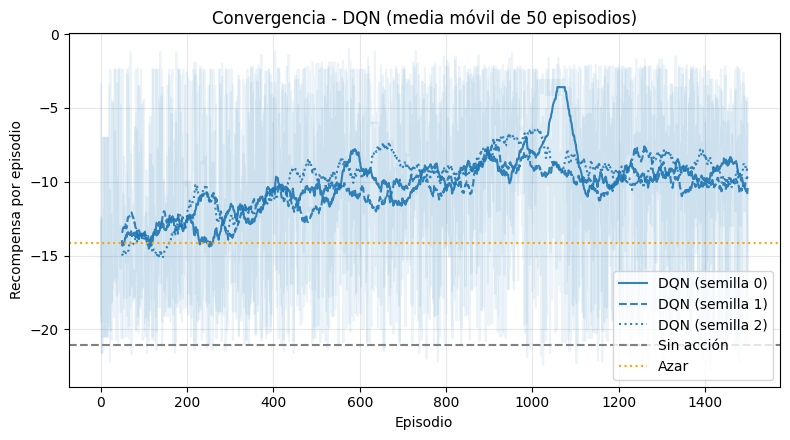

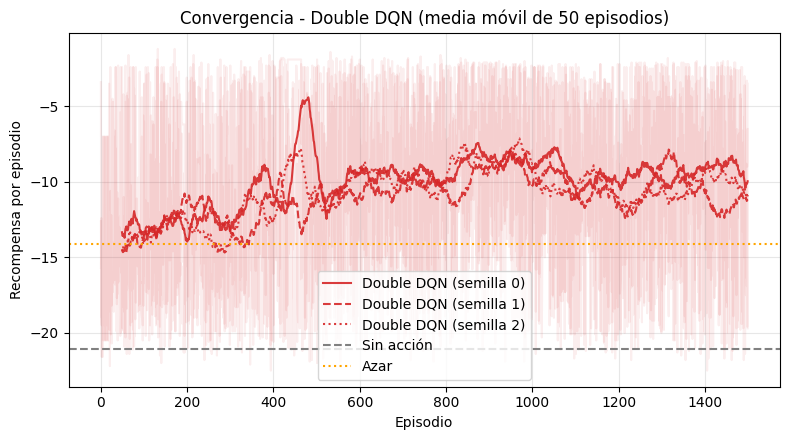

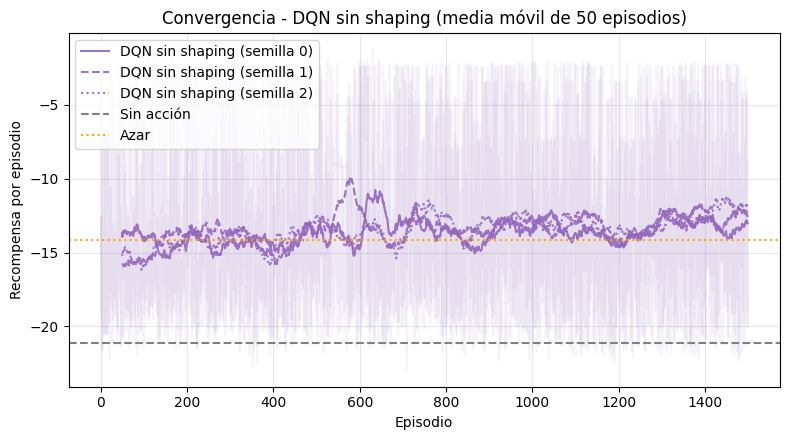

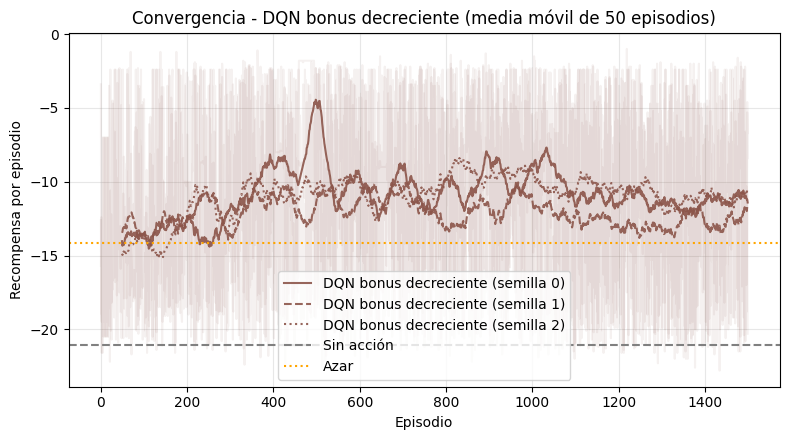

In [8]:
VENTANA = min(50, max(2, EPISODIOS // 4))


def media_movil(x, ventana=VENTANA):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(ventana) / ventana, mode="valid")


def graficar_convergencia(nombre, color):
    plt.figure(figsize=(8, 4.5))
    estilos = ["-", "--", ":", "-."]   # un estilo distinto por semilla para poder distinguirlas
    for i, (rec, _) in enumerate(historial[nombre]):
        plt.plot(rec, color=color, alpha=0.08)
        plt.plot(np.arange(VENTANA - 1, len(rec)), media_movil(rec), color=color, alpha=0.9,
                 linestyle=estilos[i % len(estilos)], label=f"{nombre} (semilla {SEMILLAS_ENTRENAMIENTO[i]})")
    plt.axhline(resultados_baselines["Sin acción"]["recompensa"].mean(), color="gray", ls="--", label="Sin acción")
    plt.axhline(resultados_baselines["Azar"]["recompensa"].mean(), color="orange", ls=":", label="Azar")
    plt.xlabel("Episodio")
    plt.ylabel("Recompensa por episodio")
    plt.title(f"Convergencia - {nombre} (media móvil de {VENTANA} episodios)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    archivo = os.path.join(CARPETA_RESULTADOS, f"convergencia_{nombre.replace(' ', '_').lower()}.png")
    plt.savefig(archivo, dpi=150)
    plt.show()


colores = {"DQN": "tab:blue", "Double DQN": "tab:red", "DQN sin shaping": "tab:purple",
           "DQN bonus decreciente": "tab:brown"}
for nombre in AGENTES:
    graficar_convergencia(nombre, colores[nombre])

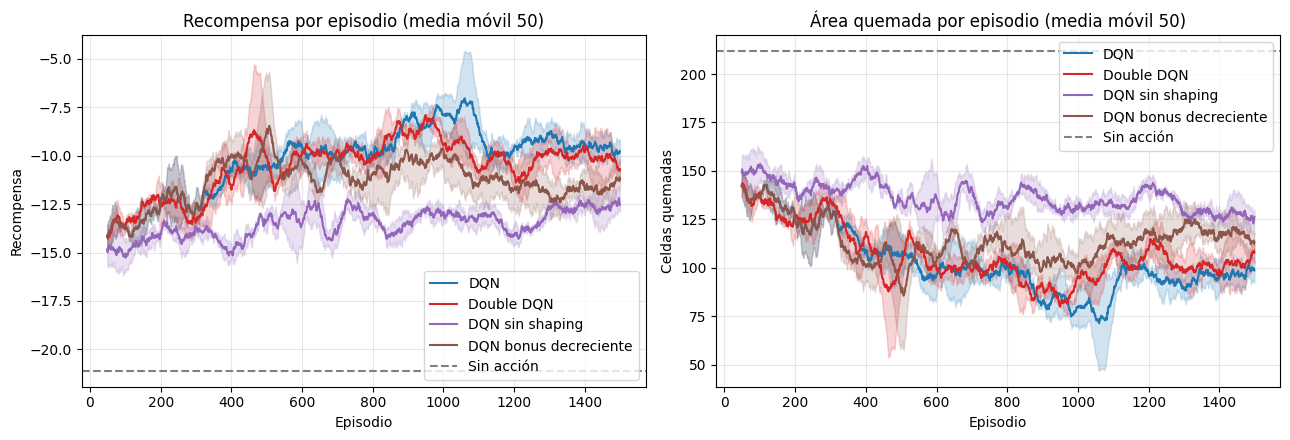

In [9]:
# Comparativa: promedio entre semillas (la banda es +-1 desvío)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre in AGENTES:
    for k, (titulo, ylabel) in enumerate([("Recompensa por episodio", "Recompensa"),
                                          ("Área quemada por episodio", "Celdas quemadas")]):
        curvas = np.stack([media_movil(h[k]) for h in historial[nombre]])
        media, desvio = curvas.mean(0), curvas.std(0)
        x = np.arange(VENTANA - 1, VENTANA - 1 + len(media))
        ejes[k].plot(x, media, color=colores[nombre], label=nombre)
        ejes[k].fill_between(x, media - desvio, media + desvio, color=colores[nombre], alpha=0.2)
        ejes[k].set_title(titulo + f" (media móvil {VENTANA})")
        ejes[k].set_xlabel("Episodio")
        ejes[k].set_ylabel(ylabel)
ejes[0].axhline(resultados_baselines["Sin acción"]["recompensa"].mean(), color="gray", ls="--", label="Sin acción")
ejes[1].axhline(resultados_baselines["Sin acción"]["area"].mean(), color="gray", ls="--", label="Sin acción")
for e in ejes:
    e.legend()
    e.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, "comparativa_dqn_vs_double_dqn.png"), dpi=150)
plt.show()

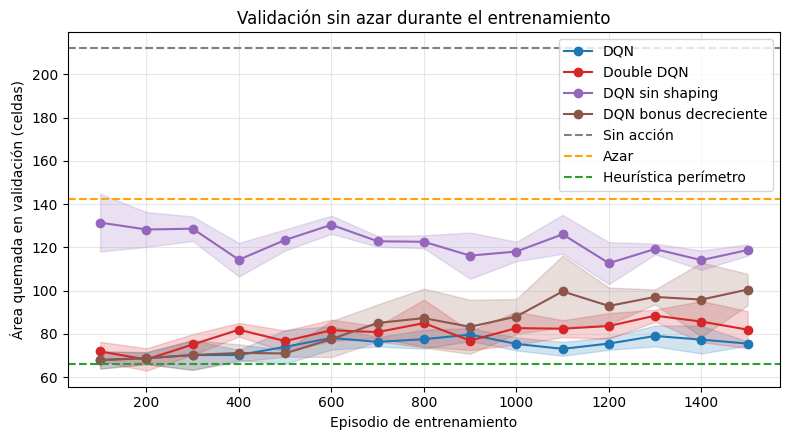

In [10]:
# Curva de validación SIN azar. La de entrenamiento mejora en parte solo porque epsilon
# baja (menos acciones al azar), así que esta es la que mejor muestra si el agente aprendió.
plt.figure(figsize=(8, 4.5))
for nombre in AGENTES:
    x = [e for e, _ in agentes_entrenados[nombre][0].evals]
    curvas = np.array([[a for _, a in ag.evals] for ag in agentes_entrenados[nombre]])
    media = curvas.mean(0)
    plt.plot(x, media, marker="o", color=colores[nombre], label=nombre)
    if len(curvas) > 1:
        plt.fill_between(x, media - curvas.std(0), media + curvas.std(0), color=colores[nombre], alpha=0.2)
for nombre_base, color_base in [("Sin acción", "gray"), ("Azar", "orange"), ("Heurística perímetro", "tab:green")]:
    plt.axhline(resultados_baselines[nombre_base]["area"].mean(), color=color_base, ls="--", label=nombre_base)
plt.xlabel("Episodio de entrenamiento")
plt.ylabel("Área quemada en validación (celdas)")
plt.title("Validación sin azar durante el entrenamiento")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, "validacion_durante_entrenamiento.png"), dpi=150)
plt.show()

## 8. Evaluación final

Evalúo los agentes ya entrenados en 50 escenarios fijos que no se usaron para
entrenar (epsilon = 0, o sea siempre la mejor acción según la red) y comparo con los
baselines sobre los mismos escenarios.

Política                 Recompensa     Área quemada
Sin acción               -21.10 ± 8.20     212.0 ±  82.0
Azar                     -14.14 ± 5.43     142.4 ±  54.3
Heurística perímetro      -6.51 ± 3.75      66.1 ±  37.5
DQN                       -7.52 ± 4.74      76.2 ±  47.4
Double DQN                -7.39 ± 4.45      74.9 ±  44.5
DQN sin shaping          -12.17 ± 5.13     122.7 ±  51.3
DQN bonus decreciente     -7.32 ± 4.43      74.2 ±  44.3


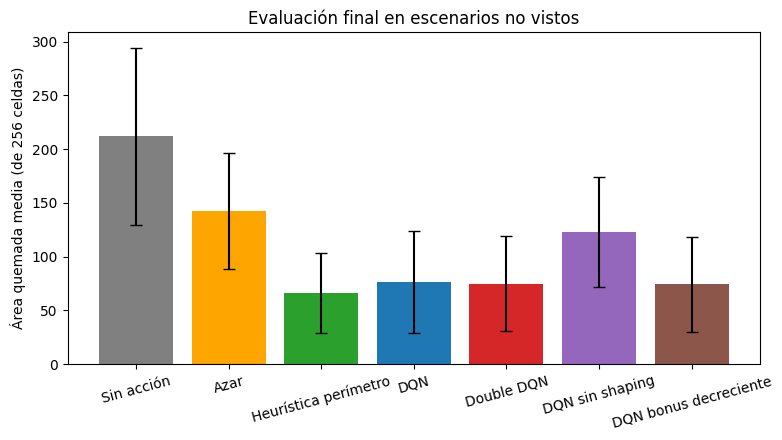

In [11]:
resultados_finales = dict(resultados_baselines)
for nombre in AGENTES:
    recs, areas = [], []
    for agente in agentes_entrenados[nombre]:
        politica = lambda e, o, ag=agente: ag.elegir_accion(o, 0.0)
        r, a = evaluar(env, politica, SEMILLAS_EVALUACION)
        recs.append(r)
        areas.append(a)
    resultados_finales[nombre] = {"recompensa": np.concatenate(recs), "area": np.concatenate(areas)}

print(f"{'Política':22s} {'Recompensa':>12s} {'Área quemada':>16s}")
for nombre, res in resultados_finales.items():
    print(f"{nombre:22s} {res['recompensa'].mean():8.2f} ± {res['recompensa'].std():4.2f} "
          f"{res['area'].mean():9.1f} ± {res['area'].std():5.1f}")

nombres = list(resultados_finales)
medias = [resultados_finales[n]["area"].mean() for n in nombres]
desvios = [resultados_finales[n]["area"].std() for n in nombres]
plt.figure(figsize=(8, 4.5))
plt.bar(nombres, medias, yerr=desvios, capsize=4,
        color=["gray", "orange", "tab:green"] + [colores[n] for n in AGENTES])
plt.ylabel(f"Área quemada media (de {N_ACCIONES} celdas)")
plt.title("Evaluación final en escenarios no vistos")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, "evaluacion_final.png"), dpi=150)
plt.show()

## 9. Cómo se ve lo que hace el agente

Mismo escenario jugado con distintas políticas. Verde = sin quemar, negro = quemado,
azul = cortafuego, rojo = ardiendo.

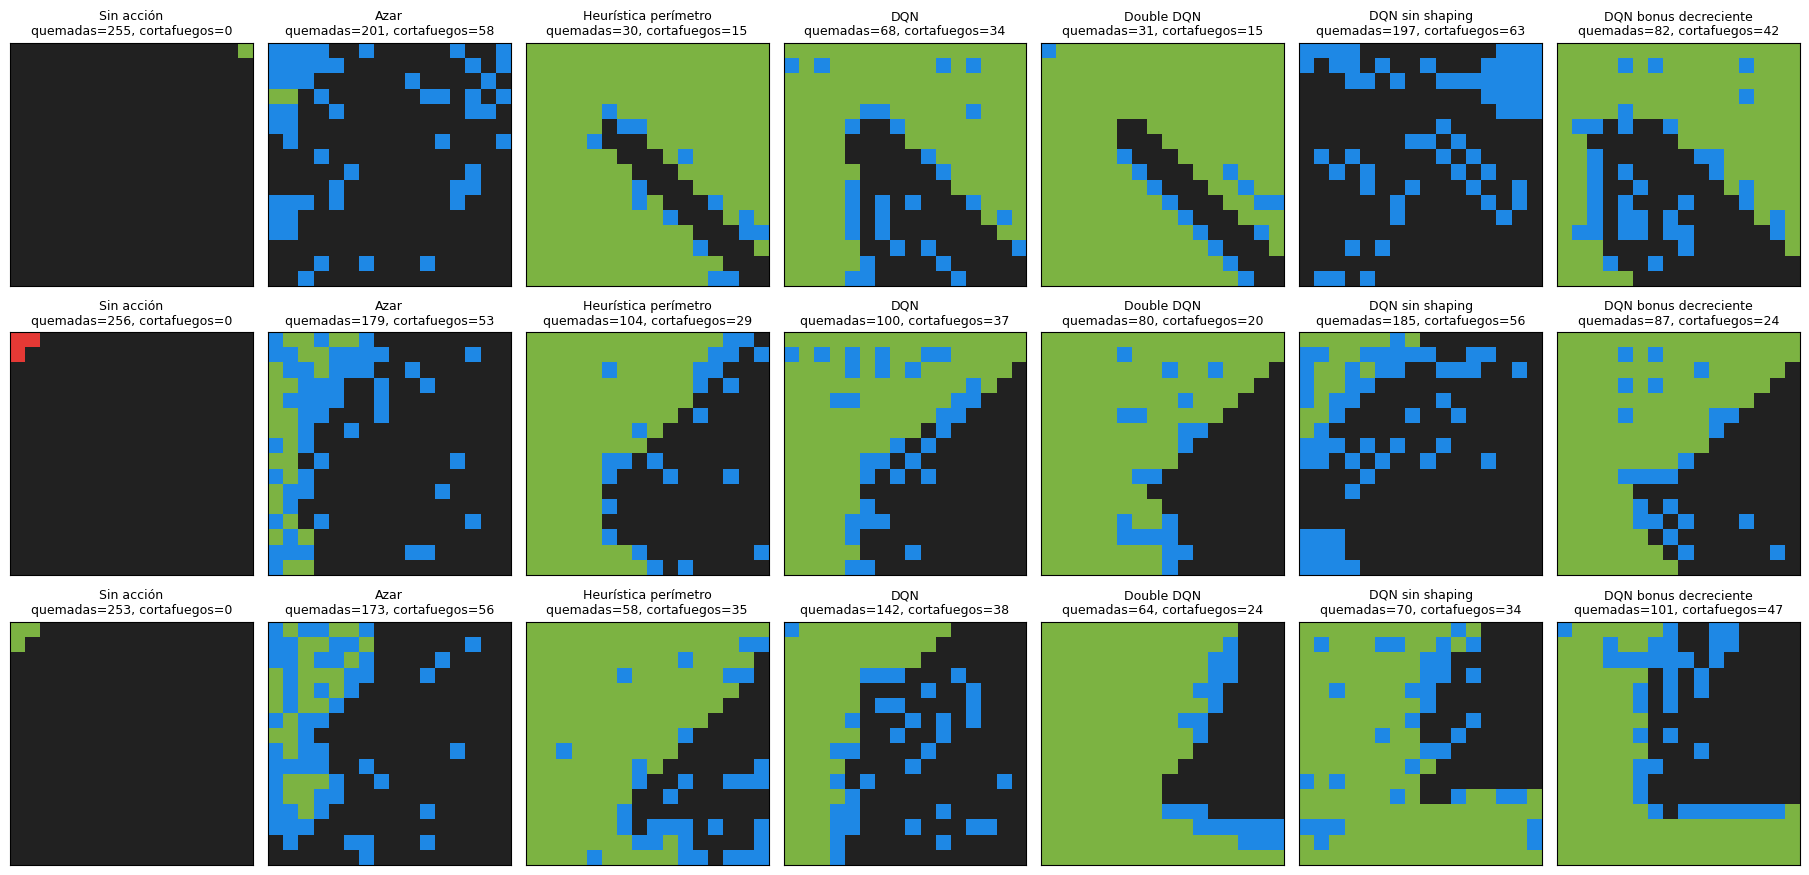

In [18]:
from IPython.display import display

cmap = ListedColormap(["#7cb342", "#e53935", "#212121", "#1e88e5"])   # orden de BurnStatus 0..3


def dibujar(ax, mapa, titulo):
    ax.imshow(np.clip(mapa, 0, 3), cmap=cmap, vmin=0, vmax=3)
    ax.set_title(titulo, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])


politicas_visual = [("Sin acción", politica_sin_accion), ("Azar", politica_azar),
                    ("Heurística perímetro", politica_perimetro)]
# un mapa por cada agente entrenado (el de la semilla 0)
for nombre in AGENTES:
    politicas_visual.append((nombre, lambda e, o, ag=agentes_entrenados[nombre][0]: ag.elegir_accion(o, 0.0)))

semillas_visual = SEMILLAS_EVALUACION[:3]

# Primero juego todos los episodios y me quedo con una copia del mapa final. SimFire
# dibuja con matplotlib sobre los ejes "actuales" cuando crea un escenario, y si ya
# tengo mi figura armada me escribe encima o abre otra figura y plt.savefig guarda esa
# en blanco. Por eso dibujo después.
mapas_finales = {}
for i, s in enumerate(semillas_visual):
    for j, (nombre, pol) in enumerate(politicas_visual):
        np.random.seed(s)
        _, area, lineas = jugar_episodio(env, pol, s)
        mapas_finales[i, j] = (env.sim.fire_map.copy(), area, lineas)
plt.close("all")

fig, ejes = plt.subplots(len(semillas_visual), len(politicas_visual), figsize=(2.6 * len(politicas_visual), 3 * len(semillas_visual)))
ejes = np.atleast_2d(ejes)
for (i, j), (mapa, area, lineas) in mapas_finales.items():
    dibujar(ejes[i, j], mapa, f"{politicas_visual[j][0]}\nquemadas={area}, cortafuegos={lineas}")
fig.tight_layout()
fig.savefig(os.path.join(CARPETA_RESULTADOS, "mapas_politicas.png"), dpi=150)
display(fig)
plt.close("all")

## 10. Guardar resultados

Guardo los números crudos por si los necesito para el informe.

In [13]:
resumen = {nombre: {"recompensa_media": float(res["recompensa"].mean()),
                    "recompensa_std": float(res["recompensa"].std()),
                    "area_media": float(res["area"].mean()),
                    "area_std": float(res["area"].std())}
           for nombre, res in resultados_finales.items()}
with open(os.path.join(CARPETA_RESULTADOS, "resumen.json"), "w") as f:
    json.dump(resumen, f, indent=2)

np.savez(os.path.join(CARPETA_RESULTADOS, "curvas_entrenamiento.npz"),
         **{f"{nombre}_semilla{SEMILLAS_ENTRENAMIENTO[i]}_{k}": h[j]
            for nombre in AGENTES
            for i, h in enumerate(historial[nombre])
            for j, k in enumerate(["recompensa", "area"])})
print("Resultados guardados en", CARPETA_RESULTADOS)

Resultados guardados en resultados
